# 1. Librerías

In [3]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import ValidationCurveDisplay, cross_val_predict

import utils.constantes as cte
from utils import modelado as mod

%matplotlib inline

np.random.seed(cte.semilla)

# 2. Train - Test

Datos provenientes de EDA, depurados pero con registros nulos aún, con partición estratificada 80% train, 20% test.

In [4]:
# Misma partición del grupo.
X_train, X_test, y_train, y_test = mod.cargar_datos()

print("Train:", X_train.shape)
print("Proporción de clases:",y_train.value_counts(normalize=True).sort_index().round(2).to_dict())

Train: (1803, 30)
Proporción de clases: {0: 0.5, 1: 0.3, 2: 0.2}


In [5]:
def curva_validacion(busqueda, parametro, valores, titulo):
    """Representa train y validación con media ± desviación, modificando un hiperparámetro."""

    ValidationCurveDisplay.from_estimator(
        busqueda.best_estimator_, X_train,y_train,
        param_name=parametro,
        param_range=valores,
        cv=mod.validador,
        scoring=mod.metrica,
        std_display_style="fill_between",
        n_jobs=-1
    )

    plt.title(titulo)
    plt.ylabel("F1 macro")
    plt.show()

# 3. Balanceo

In [23]:
rejilla_lda = [
    #Solver minimos cuadrados, con covarianza regularizada según el ruido
    {"modelo__solver": ["lsqr"],
    "modelo__shrinkage": [None, "auto", 0.1, 0.5, 0.9],},
    #Solver con descomposición de autovalores, con covarianza regularizada según el ruido
    {"modelo__solver": ["eigen"],
    "modelo__shrinkage": [None, "auto", 0.1, 0.5, 0.9],},]

busquedas_lda, tablas_balanceo_lda = {}, []

# LDA no admite class_weight, probamos sin balanceo, SMOTENC y los dos métodos de undersampling
for balanceo in [None, "smotenc", "tomek", "enn"]:
    busqueda = mod.crear_busqueda(mod.crear_pipeline(LinearDiscriminantAnalysis(),balanceo=balanceo), rejilla_lda)
    busquedas_lda[balanceo] = busqueda.fit(X_train,y_train)
    tablas_balanceo_lda.append(mod.tabla_resultados(busqueda,f"lda | {balanceo}"))

balanceo_resultados_lda = pd.concat(tablas_balanceo_lda)
display(balanceo_resultados_lda[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"]].round(3)
)

print("\nMejores hiperparámetros:\n")

for modelo, params in balanceo_resultados_lda["mejores_parametros"].items():
    print(f"{modelo}:")
    print(params)
    print()

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
lda | None,0.660,0.038,0.681,0.059,0.698,0.017
lda | smotenc,0.636,0.028,0.759,0.052,0.611,0.021
lda | tomek,0.647,0.040,0.717,0.069,0.675,0.019
lda | enn,0.567,0.034,0.823,0.055,0.571,0.017



Mejores hiperparámetros:

lda | None:
{'modelo__shrinkage': 0.1, 'modelo__solver': 'lsqr'}

lda | smotenc:
{'modelo__shrinkage': 0.5, 'modelo__solver': 'lsqr'}

lda | tomek:
{'modelo__shrinkage': 'auto', 'modelo__solver': 'lsqr'}

lda | enn:
{'modelo__shrinkage': None, 'modelo__solver': 'lsqr'}



In [60]:
rejilla_svm = [
    # Kernel lineal: Frontera plana
    {"modelo__kernel": ["linear"],
    "modelo__C": [0.1, 1, 10, 100],},
    # Kernel RBF: Frontera curva
    {"modelo__kernel": ["rbf"],
    "modelo__C": [0.1, 1, 10, 100],
    "modelo__gamma": ["scale", "auto", 0.01, 0.1],},
    # Kernel polinómico: Frontera adaptada a polinomio
    {"modelo__kernel": ["poly"],
    "modelo__C": [0.1, 1, 10],
    "modelo__degree": [2, 3],
    "modelo__gamma": ["scale", "auto"],},
    # Kernel sigmoide: Frontera adaptada a sigmoide
    {"modelo__kernel": ["sigmoid"],
    "modelo__C": [0.1, 1, 10],
    "modelo__gamma": ["scale", "auto"],},]

busquedas_svm, tablas_balanceo_svm = {}, []

# SVM admite class_weight, así que probamos todas las estrategias

for balanceo in [None, "class_weight", "smotenc", "tomek", "enn"]:

    busqueda = mod.crear_busqueda(mod.crear_pipeline(SVC(),balanceo=balanceo),rejilla_svm)
    busquedas_svm[balanceo] = busqueda.fit(X_train,y_train)
    tablas_balanceo_svm.append(mod.tabla_resultados(busqueda,f"svm | {balanceo}"))

    # mejor modelo encontrado
    # mejor_modelo = busquedas_svm[balanceo].best_estimator_
    # y_pred = mejor_modelo.predict(X_test)
    # print(f"\n===== {balanceo} =====")
    # print("Clases reales:")
    # print(pd.Series(y_test).value_counts().sort_index())
    # print("\nClases predichas:")
    # print(pd.Series(y_pred).value_counts().sort_index())

balanceo_resultados_svm = pd.concat(tablas_balanceo_svm)
display(balanceo_resultados_svm[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"        ]].round(3))
for modelo, params in balanceo_resultados_svm["mejores_parametros"].items():
    print(f"{modelo}:")
    print(params)
    print()

/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave


===== None =====
Clases reales:
riesgo_cardiovascular
0    226
1    135
2     90
Name: count, dtype: int64

Clases predichas:
0    242
1    124
2     85
Name: count, dtype: int64


/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



===== class_weight =====
Clases reales:
riesgo_cardiovascular
0    226
1    135
2     90
Name: count, dtype: int64

Clases predichas:
0    207
1    131
2    113
Name: count, dtype: int64

===== smotenc =====
Clases reales:
riesgo_cardiovascular
0    226
1    135
2     90
Name: count, dtype: int64

Clases predichas:
0    208
1    131
2    112
Name: count, dtype: int64


/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave


===== tomek =====
Clases reales:
riesgo_cardiovascular
0    226
1    135
2     90
Name: count, dtype: int64

Clases predichas:
0    247
1    103
2    101
Name: count, dtype: int64


/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave


===== enn =====
Clases reales:
riesgo_cardiovascular
0    226
1    135
2     90
Name: count, dtype: int64

Clases predichas:
0    280
1     36
2    135
Name: count, dtype: int64


,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
svm | None,0.649,0.029,0.676,0.041,0.694,0.026
svm | class_weight,0.648,0.018,0.728,0.045,0.644,0.185
svm | smotenc,0.636,0.022,0.726,0.054,0.636,0.116
svm | tomek,0.643,0.024,0.698,0.051,0.658,0.092
svm | enn,0.556,0.034,0.809,0.064,0.563,0.041


svm | None:
{'modelo__C': 0.1, 'modelo__kernel': 'linear'}

svm | class_weight:
{'modelo__C': 1, 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}

svm | smotenc:
{'modelo__C': 1, 'modelo__gamma': 'auto', 'modelo__kernel': 'rbf'}

svm | tomek:
{'modelo__C': 10, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}

svm | enn:
{'modelo__C': 100, 'modelo__kernel': 'linear'}



**Conclusión**

- El balanceo no mejora el rendimiento global de forma consistente. Los mejores valores de F1 macro se obtienen sin balanceo (LDA) y en (SVM), mientras que SMOTENC y ENN no aportan mejoras claras.

- Las técnicas de balanceo aumentan el recall de riesgo alto, pero reducen la precisión. Se detectan más pacientes de alto riesgo, aunque a costa de generar más falsas alarmas.

- TomekLinks ofrece el mejor compromiso entre sensibilidad y rendimiento global. Mejora ligeramente el recall manteniendo un F1 macro cercano al de los datos originales.

- ENN resulta demasiado agresivo. Aunque consigue los mayores recalls para la clase de riesgo alto, produce la mayor caída en F1 macro, por lo que no parece adecuado para este conjunto de datos.

- Los resultados sugieren que el principal problema es el solapamiento entre clases más que el desbalance (50%-30%-20%). Por ello, se seleccionan para los siguientes experimentos las configuraciones con mejor F1 macro: LDA sin balanceo y SVM sin balanceo.

***Durante la búsqueda de hiperparámetros algunas configuraciones de SVM, especialmente determinados kernels polinómicos y combinaciones con valores bajos de C, llegaron a ignorar completamente alguna de las clases, generando advertencias de sklearn sobre precisiones indefinidas***

# 4. SVM

`kernel`: tipo de frontera de decisión.
- linear: genera una frontera lineal.
- rbf: permite fronteras no lineales mediante funciones gaussianas.
- poly: utiliza transformaciones polinómicas.
- sigmoid: comportamiento similar a una neurona artificial.

`C`: penalización de los errores de clasificación.
- Valores pequeños (0.1) generan fronteras más simples.
- Valores grandes (10, 100) intentan clasificar correctamente más observaciones y pueden aumentar el sobreajuste.

`gamma`: controla la influencia de cada observación.
- Valores pequeños producen fronteras suaves.
- Valores grandes permiten fronteras más complejas.
- "scale" y "auto" calculan automáticamente el valor a partir de las características del conjunto de datos.

`degree`: grado del polinomio cuando se utiliza kernel="poly".

In [46]:
# la búsqueda óptima se obtuvo con class_weight en el experimento de balanceo

busqueda_svm = busquedas_svm[None]

print("Mejores parámetros:", busqueda_svm.best_params_)

tabla_svm = mod.tabla_resultados(busqueda_svm, "svm")
mod.guardar_resultados(busqueda_svm, "svm")

tabla_svm.round(3).T

Mejores parámetros: {'modelo__C': 0.1, 'modelo__kernel': 'linear'}


modelo,svm
f1_macro_train,0.675
f1_macro_train_std,0.011
f1_macro_val,0.649
f1_macro_val_std,0.029
precision_macro_train,0.683
precision_macro_train_std,0.011
precision_macro_val,0.654
precision_macro_val_std,0.032
recall_macro_train,0.673
recall_macro_train_std,0.01


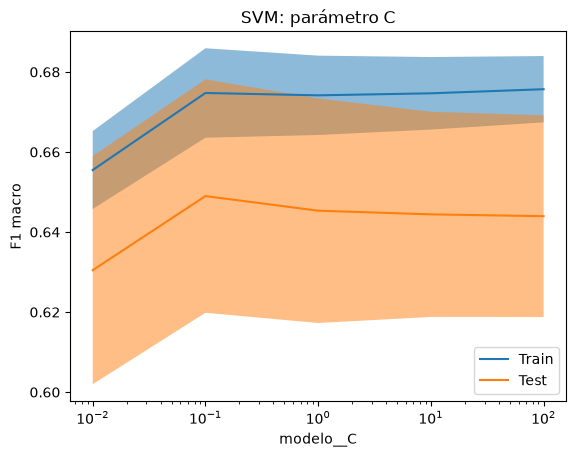

In [47]:
curva_validacion(
    busqueda_svm,
    "modelo__C",
    [0.01, 0.1, 1, 10, 100],
    "SVM: parámetro C"
)

# 5. LDA

In [52]:
# la búsqueda óptima se obtuvo sin balanceo en el experimento de balanceo

busqueda_lda = busquedas_lda[None]

print("Mejores parámetros:", busqueda_lda.best_params_)

tabla_lda = mod.tabla_resultados(busqueda_lda, "lda")
mod.guardar_resultados(busqueda_lda, "lda")

tabla_lda.round(3).T

Mejores parámetros: {'modelo__shrinkage': 0.1, 'modelo__solver': 'lsqr'}


modelo,lda
f1_macro_train,0.677
f1_macro_train_std,0.01
f1_macro_val,0.66
f1_macro_val_std,0.038
precision_macro_train,0.684
precision_macro_train_std,0.01
precision_macro_val,0.666
precision_macro_val_std,0.042
recall_macro_train,0.675
recall_macro_train_std,0.009


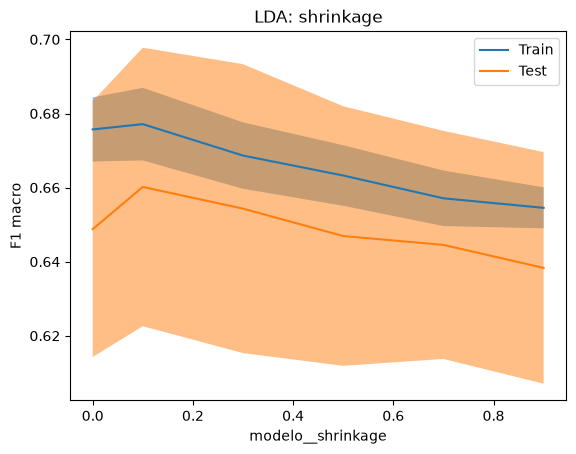

In [53]:
curva_validacion(
    busqueda_lda,
    "modelo__shrinkage",
    [0.0, 0.1, 0.3, 0.5, 0.7, 0.9],
    "LDA: shrinkage"
)

# 4. Comparación de modelos

In [54]:
busquedas = {"lda": busqueda_lda,"svm": busqueda_svm,}
comparacion = pd.concat([tabla_lda,tabla_svm,])
display(comparacion[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"]]
    .sort_values("f1_macro_val",ascending=False).round(3))
print("Mejores hiperparámetros")
display(comparacion[["mejores_parametros"]])


,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
lda,0.660,0.038,0.681,0.059,0.698,0.017
svm,0.649,0.029,0.676,0.041,0.694,0.026


Mejores hiperparámetros


,mejores_parametros
modelo,
lda,"{'modelo__shrinkage': 0.1, 'modelo__solver': '..."
svm,"{'modelo__C': 0.1, 'modelo__kernel': 'linear'}"


**Conclusión**

- LDA obtiene el mejor rendimiento global. Alcanza un F1 macro de 0,660, ligeramente superior al de SVM (0,649), así como un mejor recall de la clase de riesgo alto (0,681 frente a 0,676) y una mayor precisión (0,698 frente a 0,694).

- Ambos modelos muestran una buena capacidad de generalización. La diferencia entre entrenamiento y validación es muy baja en los dos casos (0,017 en LDA y 0,026 en SVM), lo que indica ausencia de sobreajuste importante y una estimación estable del rendimiento futuro.

- La regularización ligera mejora LDA. La curva de validación muestra que los mejores resultados aparecen para valores bajos de shrinkage (≈ 0,1). A medida que aumenta la regularización, el rendimiento en validación disminuye gradualmente, lo que indica que una simplificación excesiva de la matriz de covarianzas elimina información útil para separar las clases.

- SVM alcanza su mejor rendimiento con un modelo lineal sencillo. La curva de validación muestra que el máximo F1 se obtiene para C=0.1, mientras que aumentar la complejidad del modelo no aporta mejoras. Esto sugiere que las relaciones presentes en los datos son relativamente simples y que una frontera de decisión más compleja no mejora la capacidad predictiva.

- Las diferencias entre ambos modelos son pequeñas. Los valores de F1 macro, recall y precisión son muy similares, por lo que ambos constituyen alternativas válidas para el problema. Sin embargo, LDA obtiene sistemáticamente los mejores resultados y presenta el menor sobreajuste, por lo que se considera la opción más adecuada entre los dos modelos analizados.

# 5. Fold a fold

In [55]:
folds = pd.DataFrame({
    n: pd.read_csv(
        mod.RUTA_RESULTADOS / f"{n}_folds.csv",
        index_col=0
    )["f1_macro"]
    for n in ["lda", "svm"]
})

folds["svm_menos_lda"] = folds["svm"] - folds["lda"]
folds.round(3)


,lda,svm,svm_menos_lda
fold,,,
0,0.683,0.683,0.000
1,0.709,0.678,-0.031
2,0.613,0.622,0.009
3,0.676,0.652,-0.025
4,0.620,0.610,-0.009


# 6. Matrices de confusión

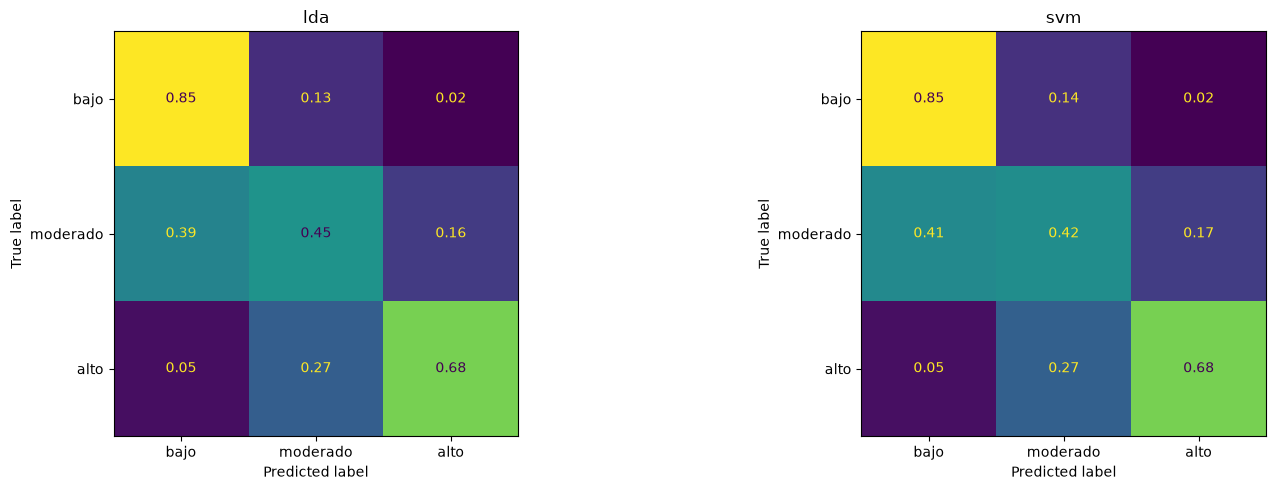

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (nombre, busqueda) in zip(axes, busquedas.items()):

    y_pred = cross_val_predict(
        busqueda.best_estimator_,
        X_train,
        y_train,
        cv=mod.validador,
        n_jobs=-1
    )

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        display_labels=["bajo", "moderado", "alto"],
        normalize="true",
        values_format=".2f",
        ax=ax,
        colorbar=False
    )

    ax.set_title(nombre)

plt.tight_layout()
plt.show()


### **Conclusión**

| | LDA | SVM |
|---|---|---|
| F1 macro (validación) | **0,660 ± 0,038** | 0,649 ± 0,029 |
| Recall de riesgo alto | **0,681** | 0,676 |
| Precisión de riesgo alto | **0,698** | 0,694 |
| Diferencia train-validación | **0,017** | 0,026 |

- **LDA es el mejor modelo según el criterio acordado**, ya que obtiene el mayor F1 macro y también supera ligeramente a SVM en recall y precisión para la clase de riesgo alto.

- **Ambos modelos generalizan bien**, con diferencias train-validación muy reducidas, lo que indica ausencia de sobreajuste relevante.

- **Las diferencias son pequeñas**, por lo que tanto LDA como SVM constituyen alternativas válidas para el problema.

- **Se selecciona LDA como candidato de este notebook debido a los resultados ligeramente superiores, contando con el problema de separación de clases**